In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [2]:
import pickle

with open('pipe.pkl', 'rb') as f:
    pipe = pickle.load(f)

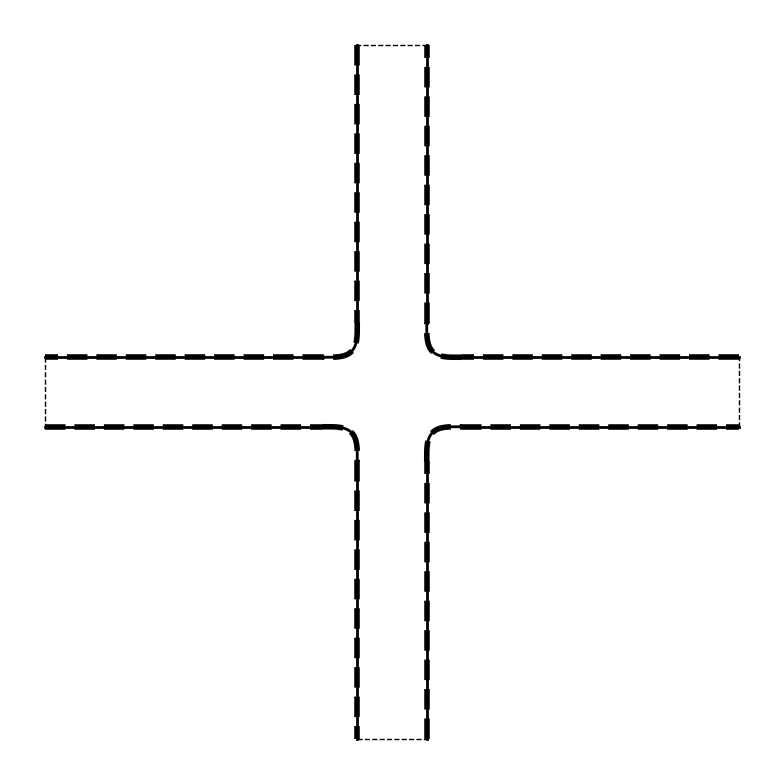

In [3]:
# Visualize the pipe geometries using the boundary plotting method
fig, ax = plt.subplots(tight_layout=True)

# Plot T-shaped pipe
ax.set_aspect('equal')
ax.axis('off')
pipe.exterior_boundary.plot_plyg_bdr(ax,color='k')

plt.show()

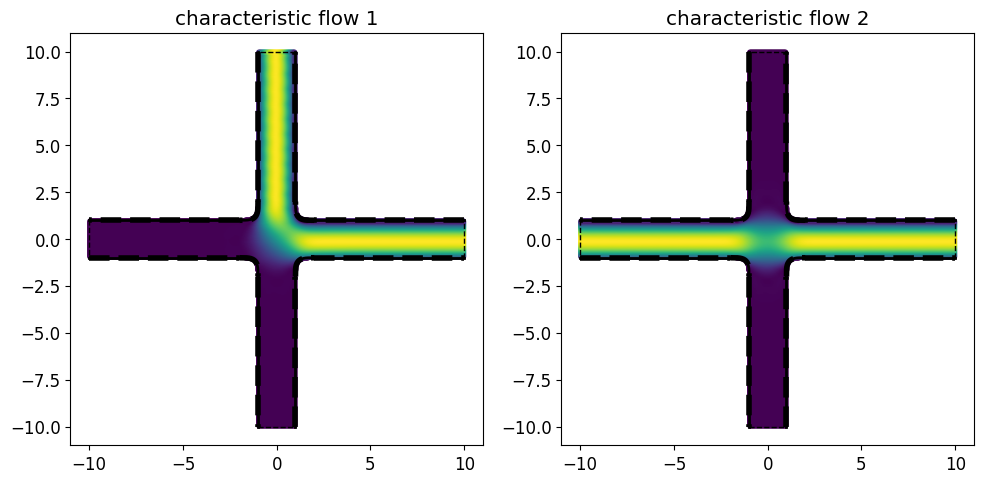

In [4]:
xs = pipe.xs
ys = pipe.ys

step = 1

fig, axes = plt.subplots(1,2, figsize=(10,10),tight_layout=True)

axes[0].set_aspect('equal')
u0,v0,p0,o0 = pipe.fields_with_fluxes(np.array([1,0,0]),0,0)
pipe.exterior_boundary.plot_plyg_bdr(axes[0], color='k')
axes[0].scatter(xs, ys, c=np.linalg.norm(np.array([u0,v0]),axis=0),s=10)
axes[0].set_title('characteristic flow 1')




axes[1].set_aspect('equal')
u1,v1,p1,o1 = pipe.fields_with_fluxes(np.array([0,1,0]),0,0)
pipe.exterior_boundary.plot_plyg_bdr(axes[1], color='k')
axes[1].scatter(xs, ys, c=np.linalg.norm(np.array([u1,v1]),axis=0),s=10)

axes[1].set_title('characteristic flow 2')

plt.show()

In [ ]:
pipe = None

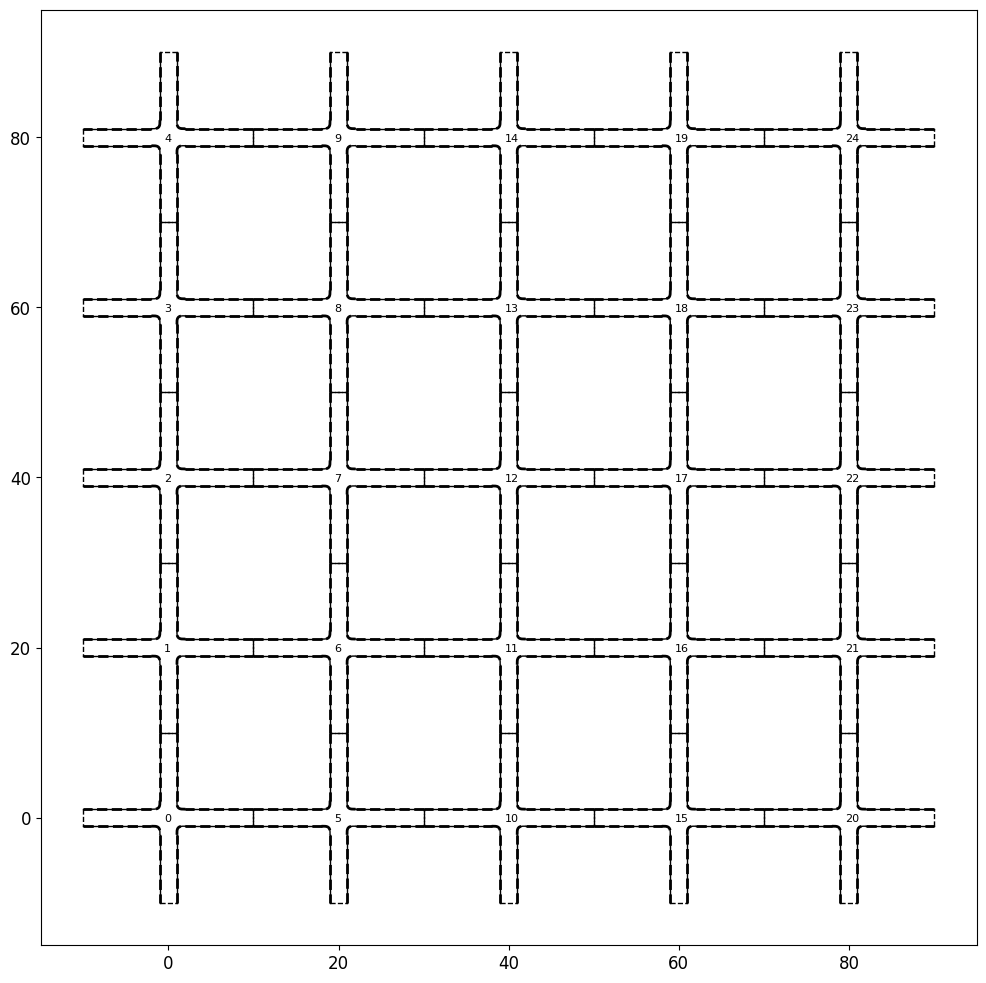

In [8]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

n_rep_x = 5
n_rep_y = 5

pipes = [RealPipe(pipe,20*i,20*j,0) for i in range(n_rep_x) for j in range(n_rep_y)]


for i,p in enumerate(pipes):
    p.plot_plyg_bdr(ax)
    x = np.mean(p.xs) - 0.5
    y = np.mean(p.ys) - 0.5
    ax.text(x,y,f'{i}',fontsize=8)

ax.set_aspect('equal')
# ax.axis('off')

plt.show()

#### re-development of the pipe-system solver 

fundamental variables: 
- the coefficients of characteristic flows of all pipes

fundamental constraints:
- pressure is path-irrelavent
- flux is preserved at each connection

boundary conditions (imposed by users):
- either pressures at each boundary 
- or flux at each boundary


nodes are the connection point or boundary let. 

In [9]:
flows = []
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        flows.append((ip,iflow))
flows = list(enumerate(flows))
flows_idx2flow = dict(flows)
flow2flows_idx = {flow:idx for idx,flow in flows}

In [10]:
from itertools import product

In [11]:
_traverse = dict()

for ip,p in enumerate(pipes):
    for il,l in enumerate(p.lets):
        _traverse[(ip,il)] = (p,l)
        
_nodes = []


# internal nodes
for ((ip1,il1), (p1,l1)),((ip2,il2), (p2,l2)) in product(_traverse.items(),repeat=2):
    if ip1>=ip2: 
        continue
    if l1.almost_match(l2):
        # create an internal node
        _nodes.append({
            'node_type': 'internal',
            'let0': (ip1,il1),
            'let1': (ip2,il2),
            'pos': (l1.x,l1.y),
        })
        
# boundary nodes
for ((ip,il), (p,l)) in _traverse.items():
    pos = np.array([l.x,l.y])
    dist = np.min([np.linalg.norm(pos - n['pos'])  for n in _nodes])
    if dist < 1e-6:
        continue
    
    _nodes.append({
        'node_type': 'boundary',
        'let': (ip,il),
        'pos': (l.x,l.y),
    })

In [12]:
# creating the flux equations at each node
n_flows = len(flows)
flux_equations = []
for n in _nodes:
    if n['node_type'] != 'internal':
        continue
    
    let0 = n['let0']
    let1 = n['let1']
    
    equation = np.zeros(n_flows)
    p0,l0 = let0
    p1,l1 = let1
    
    for i, (ip,iflow) in flows:
        
        '''
        this flow is from the 0-th let to the i-flow-1 -th let in the pipe ip. 
        '''
        if ip == p0 and l0 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p1 and l1 == iflow + 1:
            equation[i] = -1 # flowing into the node
        if ip == p0 and l0 == 0:
            equation[i] = 1 # this flow flows out of the node
        if ip == p1 and l1 == 0:
            equation[i] = 1 # this flow flows out of the node
        
    
    flux_equations.append(equation)
flux_equations=np.array(flux_equations)


#### pressure drops 

Given an edge, find the pipe, and find the two lets, and two lets l0 and l1 in the pipe, what does each flow in the pipe affect the pressure drop between l0 and l1 ?

In [13]:
# create the graphs with all the edges
edges = []

def fn_lets(node):
    if node['node_type'] == 'internal':
        return [node['let0'],node['let1']]
    else:
        return [node['let']]
    
for ip,p in enumerate(pipes):
    for iflow in range(p.n_flows):
        
        start_let = (ip,0)    
        start_node_idx = [inode for inode,n in enumerate(_nodes) if start_let in fn_lets(n)][0]
        end_let = (ip,iflow+1)
        end_node_idx = [inode for inode,n in enumerate(_nodes) if end_let in fn_lets(n)][0]
        
        edges.append((start_node_idx,end_node_idx))


In [14]:
def fn_n2l(n):
    if n['node_type'] == 'internal':
        return [n['let0'],n['let1']]
    else:
        return [n['let']]

edges2pressure_drop = {}

for e in edges:
    n0 = _nodes[e[0]]
    n1 = _nodes[e[1]]
    
    l0 = fn_n2l(n0)
    l1 = fn_n2l(n1)
    
    cap = [(ll,lll) for ll, lll in product(l0,l1) if ll[0] == lll[0]]
    assert len(cap) == 1
    
    cap = cap[0]
    
    p = cap[0][0]
    l0 = cap[0][1]
    l1 = cap[1][1]
    
    pd = pipes[p].pressure_drops
    
    if l0 == 0:
        pd = pd[:,l1-1]
    elif l1 == 0:
        pd = -pd[:,l0-1]
    else: 
        pd = pd[:,l1-1] - pd[:,l0-1]
    
    pdf = np.zeros(len(flows))
    
    idx = [i for i,(j,k) in flows if j==p]
    
    pdf[idx] = pd
    
    edges2pressure_drop[e] = pdf
    
    
    reverse_e = (e[1],e[0])
    edges2pressure_drop[reverse_e] = -pdf

In [15]:
import networkx as nx

g = nx.Graph()
g.add_nodes_from(range(len(_nodes)))
g.add_edges_from(edges)

cycles = nx.cycle_basis(g)


# pressure drop equations

pressure_drop_equations = []
for c in cycles:
    eq = np.zeros(len(flows))
    for e in zip(c,c[1:]+[c[0]]):
        eq += edges2pressure_drop[e]
    
    pressure_drop_equations.append(eq)

pressure_drop_equations = np.vstack(pressure_drop_equations)

In [16]:
laws = np.vstack([pressure_drop_equations,flux_equations])

#### create the equation for the flux at all the boundary lets

In [17]:
# prescribe the pressure at boundary let. 


p_equations = []
boundary_lets = [inode for inode,n in enumerate(_nodes) if n['node_type'] == 'boundary']

n0 = boundary_lets[0]
for n1 in boundary_lets[1:]:
    
    path = nx.shortest_path(g, source=n0, target=n1)
    equation = np.zeros(n_flows)
    
    for e in zip(path,path[1:]):
        equation += edges2pressure_drop[e]
        
    p_equations.append(equation)
p_equations = np.array(p_equations)

In [18]:
    
def pressure_to_flow(boundary_pressure,verbose=False):
    assert len(boundary_pressure) == len(boundary_lets), f'pressure should have {len(boundary_lets)} elements'
    # assert np.isclose(np.sum(pressure),0), f'net pressure should be zero'
    
    pressure_drop = -boundary_pressure[1:] + boundary_pressure[:-1]
    
    
    A = np.vstack([p_equations,laws])
    
    if verbose:
        print(f'condition number is {np.linalg.cond(A)}')
    
    
    b = np.concatenate([pressure_drop,np.zeros(laws.shape[0])])
    
    import time
    start_time = time.perf_counter()
    x = np.linalg.solve(A,b)
    end_time = time.perf_counter()
    print(f'time taken is {end_time - start_time} seconds')
    
    return x
    

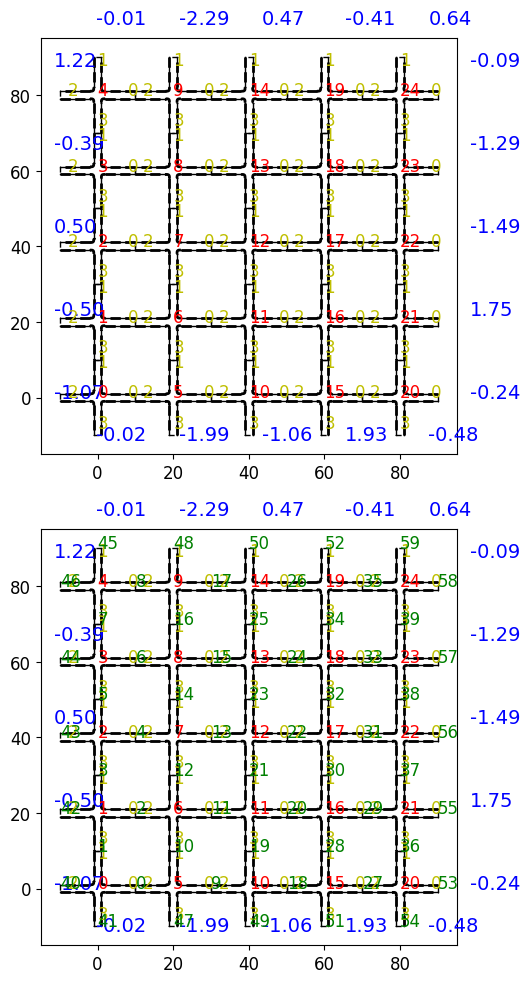

In [24]:
fig,axes = plt.subplots(2,1,figsize=(20,10), tight_layout=True)

bpressures = np.random.randn(len(boundary_lets))

for blet,bp in zip(boundary_lets,bpressures):
    blet = _nodes[blet]
    pos = np.array(blet['pos'])
    center = np.array([5,2.5])
    
    t = 0.1
    
    pos = (1+t)*pos - t*center
    
    axes[0].text(pos[0],pos[1],f'{bp:.2f}',fontsize=14,color='b')
    axes[1].text(pos[0],pos[1],f'{bp:.2f}',fontsize=14,color='b')
    
for ip,p in enumerate(pipes):
    c = np.array([np.mean(p.xs),np.mean(p.ys)])
    
    p.plot_plyg_bdr(axes[0], color='k')
    p.plot_plyg_bdr(axes[1], color='k')
    
    axes[0].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
    axes[1].text(c[0],c[1],f'{ip}',fontsize=12,color='r')
    
    for il,l in enumerate(p.lets):
        pos = np.array([l.x,l.y])*0.8 + c*0.2
        axes[0].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')
        axes[1].text(pos[0],pos[1],f'{il}',fontsize=12,color='y')

for inode,n in enumerate(_nodes):
    plt.text(n['pos'][0],n['pos'][1],f'{inode}',fontsize=12,color='g')
    

axes[0].set_aspect('equal')
axes[1].set_aspect('equal')
    

In [25]:
flow_coef = pressure_to_flow(bpressures,verbose=True)

condition number is 120.0878323784954
time taken is 0.0649780830135569 seconds


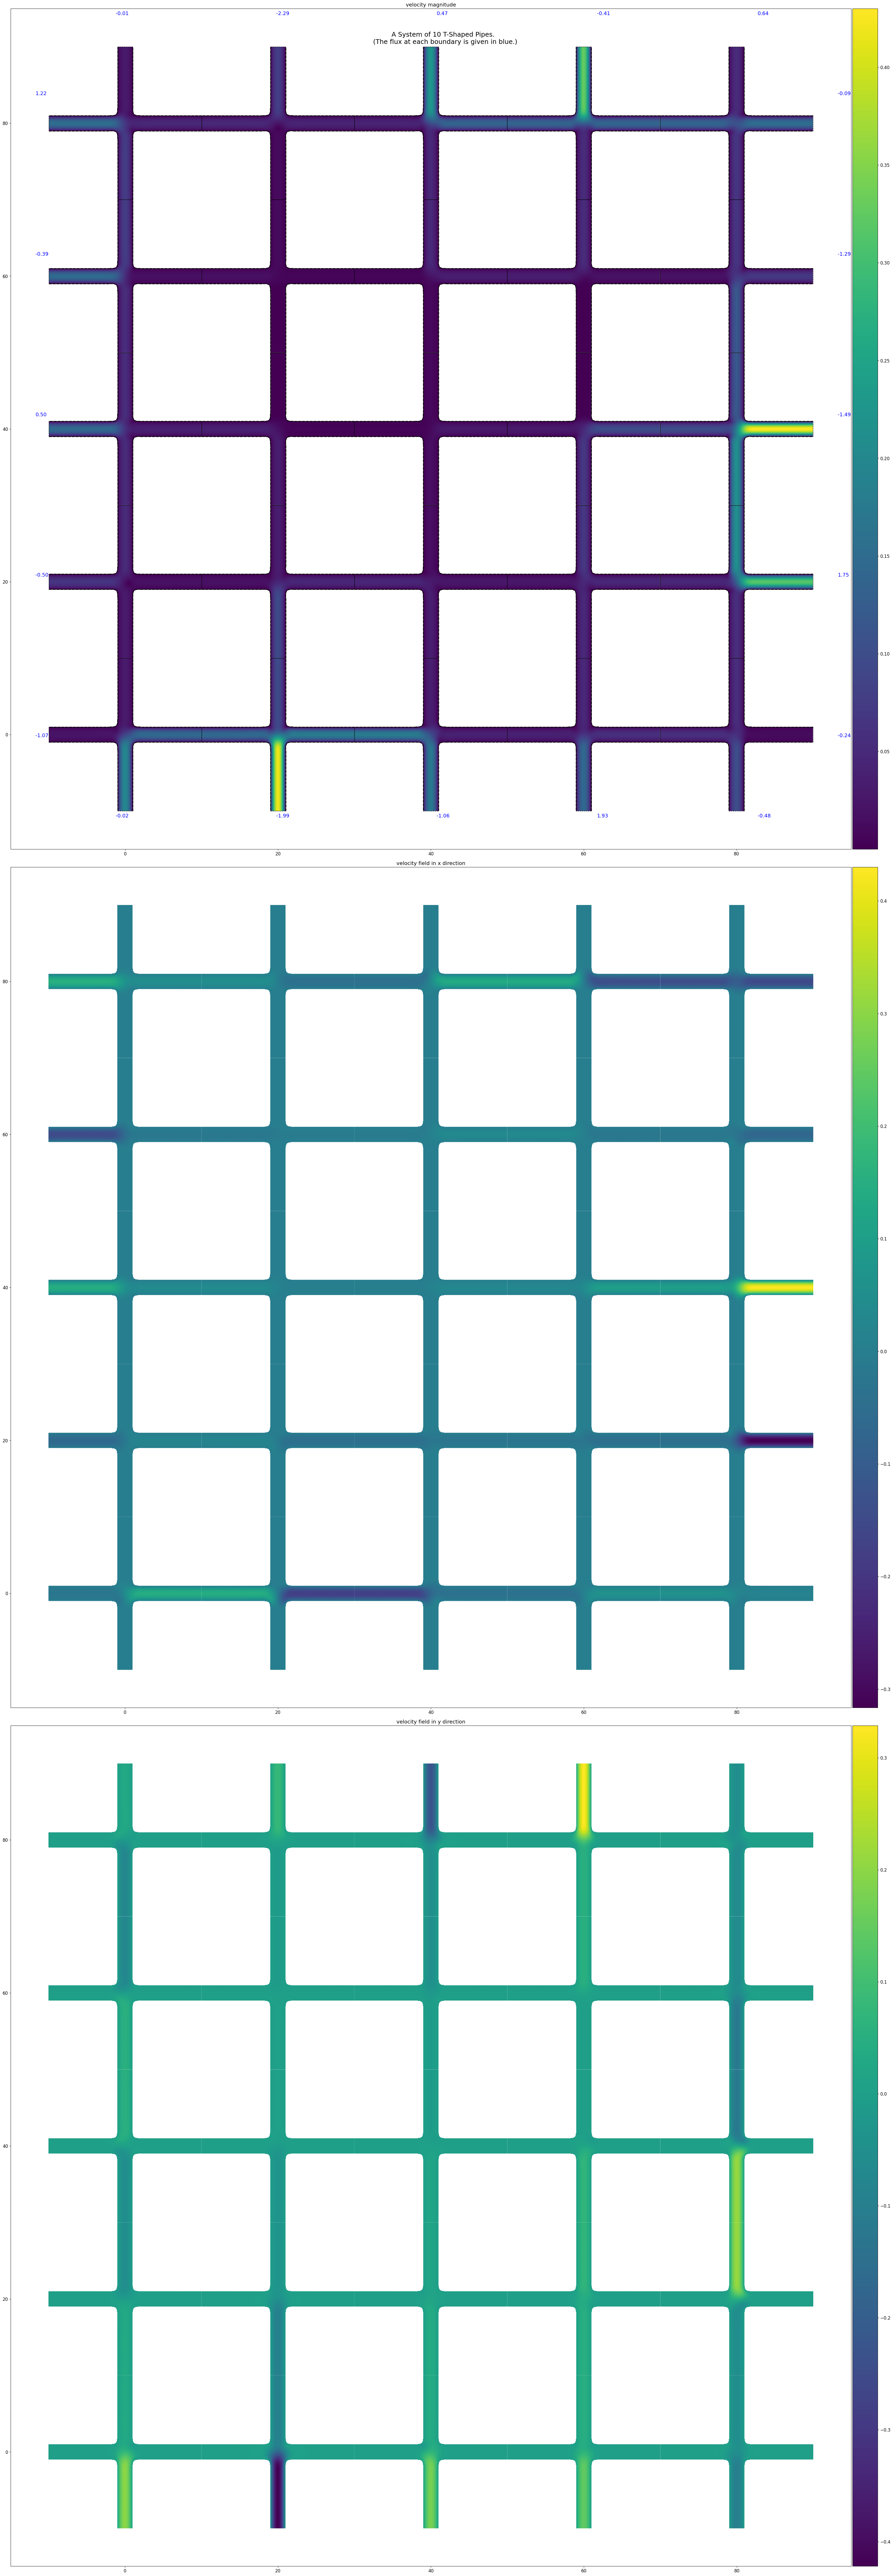

In [31]:
us = []
vs = []
xs = []
ys = []

for pidx,p in enumerate(pipes):    
    flow_idx = [i for i,(j,k) in flows if j==pidx] 
    coef = flow_coef[flow_idx]
    u,v,_,_ =  p.fields_with_fluxes(coef,0,0)
    
    # if pidx == 1:
    us.append(u)
    vs.append(v)
    xs.append(p.xs)
    ys.append(p.ys)

us = np.concatenate(us)
vs = np.concatenate(vs)
xs = np.concatenate(xs)
ys = np.concatenate(ys)

fig,axes = plt.subplots(3,1,figsize=(100,100),tight_layout=True)


for blet,bp in zip(boundary_lets,bpressures):
    blet = _nodes[blet]
    pos = np.array(blet['pos'])
    center = np.array([5,2.5])
    
    t = 0.05
    
    pos = (1+t)*pos - t*center + np.array([-1,-0.2])
    
    axes[0].text(pos[0],pos[1],f'{bp:.2f}',fontsize=14,color='b')

for ax in axes:
    ax.set_aspect('equal')    
    
    
axes[0].scatter(xs,ys,c=np.sqrt(us**2+vs**2),s=1)
axes[0].set_title('velocity magnitude')

for ip,p in enumerate(pipes):
    c = np.array([np.mean(p.xs),np.mean(p.ys)])

    p.plot_plyg_bdr(axes[0], color='k')

from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[0])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[0].collections[0], cax=cax)



axes[1].set_title('velocity field in x direction')
axes[1].scatter(xs,ys,c=us,s=1)
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[1])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[1].collections[0], cax=cax)



axes[2].scatter(xs,ys,c=vs,s=1)
axes[2].set_title('velocity field in y direction')
from mpl_toolkits.axes_grid1 import make_axes_locatable
divider = make_axes_locatable(axes[2])
cax = divider.append_axes("right", size="3%", pad=0.05)
plt.colorbar(axes[2].collections[0], cax=cax)


fig.suptitle('A System of 10 T-Shaped Pipes. \n (The flux at each boundary is given in blue.)', fontsize=18)


plt.show()